# Module 06 — Linear Model Selection and Regularization

**Applied exercises only** · ISLP, Chapter 6

**Printed textbook pages:** 286–287 (exercise starting pages)  

In [1]:
# Common imports: run this cell once before starting the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from ISLP import load_data
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV, Lasso
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(1)


def cp_score(X, y, cols, sigma2):
    """Mallow's Cp = (RSS + 2 d sigma^2) / n for an OLS fit on `cols` (+ intercept)."""
    Xd = sm.add_constant(X[list(cols)], has_constant="add")
    rss = sm.OLS(y, Xd).fit().ssr
    return (rss + 2 * len(cols) * sigma2) / len(y)


def stepwise(X, y, direction="forward"):
    """Forward or backward stepwise selection; returns the best model of each size, chosen by RSS."""
    p = X.shape[1]
    rss = lambda cols: sm.OLS(y, sm.add_constant(X[list(cols)], has_constant="add")).fit().ssr
    path = {}
    if direction == "forward":
        current = []
        path[0] = ()
        for k in range(1, p + 1):
            best = min((c for c in X.columns if c not in current), key=lambda c: rss(current + [c]))
            current = current + [best]
            path[k] = tuple(current)
    else:
        current = list(X.columns)
        path[p] = tuple(current)
        for k in range(p - 1, -1, -1):
            drop = min(current, key=lambda c: rss([v for v in current if v != c]))
            current = [v for v in current if v != drop]
            path[k] = tuple(current)
    return path


def choose_by_cp(X, y, path):
    full = sm.OLS(y, sm.add_constant(X)).fit()
    sigma2 = full.ssr / full.df_resid
    cps = pd.Series({k: cp_score(X, y, cols, sigma2) for k, cols in path.items()}, name="Cp")
    k_best = int(cps.idxmin())
    return k_best, path[k_best], cps

---

## Exercise 8 · Applied

**Textbook: printed page 286**

In this exercise, we will generate simulated data, and will then use
this data to perform forward and backward stepwise selection.

### Exercise 8(a)

Create a random number generator and use its normal() method
to generate a predictor X of length n = 100, as well as a noise
vector ϵ of length n = 100.

In [2]:
# Exercise 8(a)
rng = np.random.default_rng(1)
X = rng.normal(size=100)
eps = rng.normal(size=100)
print(X[:5].round(3), eps[:5].round(3))

[ 0.346  0.822  0.33  -1.303  0.905] [-0.651  0.862 -0.126  0.669  1.219]


### Exercise 8(b)

Generate a response vector Y of length n = 100 according to
the model
Y = β0 + β1X + β2X2 + β3X3 + ϵ,
where β0, β1, β2, and β3 are constants of your choice.

In [3]:
# Exercise 8(b)
beta0, beta1, beta2, beta3 = 2.0, 3.0, -1.0, 0.5
Y = beta0 + beta1 * X + beta2 * X**2 + beta3 * X**3 + eps
print(f"True model: Y = {beta0} + {beta1} X + {beta2} X^2 + {beta3} X^3 + eps")

True model: Y = 2.0 + 3.0 X + -1.0 X^2 + 0.5 X^3 + eps


### Exercise 8(c)

Use forward stepwise selection in order to select a model containing the predictors X, X2, . . . , X10. What is the model obtained
according to Cp? Report the coefficients of the model obtained.

Forward path: {1: 'X1', 2: 'X2', 3: 'X3', 4: 'X10', 5: 'X4', 6: 'X5', 7: 'X8', 8: 'X9', 9: 'X7', 10: 'X6'}
Cp chooses 4 predictors: ('X1', 'X2', 'X3', 'X10')
const    2.0534
X1       2.7756
X2      -1.2410
X3       0.6119
X10      0.0003
dtype: float64


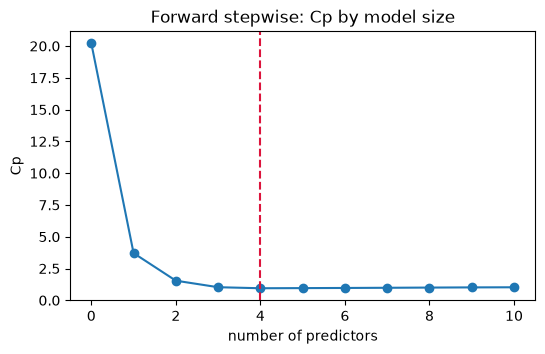

In [4]:
# Exercise 8(c)
Xpoly = pd.DataFrame({f"X{j}": X**j for j in range(1, 11)})
fwd_path = stepwise(Xpoly, Y, "forward")
k_fwd, cols_fwd, cp_fwd = choose_by_cp(Xpoly, Y, fwd_path)
print("Forward path:", {k: v[-1] for k, v in fwd_path.items() if k > 0})
print(f"Cp chooses {k_fwd} predictors: {cols_fwd}")
fit_fwd = sm.OLS(Y, sm.add_constant(Xpoly[list(cols_fwd)])).fit()
print(fit_fwd.params.round(4))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(cp_fwd.index, cp_fwd.values, marker="o")
ax.axvline(k_fwd, color="crimson", ls="--")
ax.set(xlabel="number of predictors", ylabel="Cp", title="Forward stepwise: Cp by model size")
plt.show()

### Exercise 8(d)

Repeat (c), using backwards stepwise selection. How does your
answer compare to the results in (c)?

In [5]:
# Exercise 8(d)
bwd_path = stepwise(Xpoly, Y, "backward")
k_bwd, cols_bwd, cp_bwd = choose_by_cp(Xpoly, Y, bwd_path)
print(f"Cp chooses {k_bwd} predictors: {cols_bwd}")
fit_bwd = sm.OLS(Y, sm.add_constant(Xpoly[list(cols_bwd)])).fit()
print(fit_bwd.params.round(4))
display(pd.DataFrame({"forward Cp": cp_fwd, "backward Cp": cp_bwd}).round(3))

Cp chooses 5 predictors: ('X1', 'X2', 'X6', 'X7', 'X8')
const    2.0122
X1       3.3324
X2      -1.1566
X6      -0.0916
X7       0.0267
X8       0.0205
dtype: float64


,forward Cp,backward Cp
0,20.218,20.218
1,3.711,3.711
2,1.542,1.542
3,1.028,1.318
4,0.947,1.027
5,0.957,0.964
6,0.969,0.973
7,0.984,0.977
8,1.000,0.995
9,1.014,1.008


### Exercise 8(e)

Now fit a lasso model to the simulated data, again using X, X2,
. . . , X10 as predictors. Use cross-validation to select the optimal
value of λ. Create plots of the cross-validation error as a function
of λ. Report the resulting coefficient estimates, and discuss the
results obtained.

CV-chosen lambda: 0.1760
Lasso coefficients (original scale):
X1     2.9832
X2    -0.9434
X3     0.4265
X4    -0.0000
X5     0.0000
X6    -0.0000
X7     0.0000
X8     0.0000
X9    -0.0000
X10    0.0000


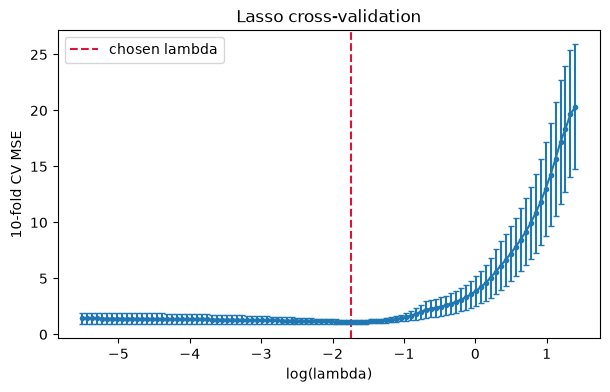

In [6]:
# Exercise 8(e)
lasso_cv = make_pipeline(StandardScaler(), LassoCV(alphas=100, cv=KFold(10, shuffle=True, random_state=0),
                                                   max_iter=100_000))
lasso_cv.fit(Xpoly, Y)
lcv = lasso_cv[-1]
print(f"CV-chosen lambda: {lcv.alpha_:.4f}")
coef_lasso = pd.Series(lcv.coef_ / lasso_cv[0].scale_, index=Xpoly.columns)   # back to original scale
print("Lasso coefficients (original scale):")
print(coef_lasso.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
mean_mse = lcv.mse_path_.mean(axis=1)
se_mse = lcv.mse_path_.std(axis=1) / np.sqrt(lcv.mse_path_.shape[1])
ax.errorbar(np.log(lcv.alphas_), mean_mse, yerr=se_mse, fmt="o-", ms=3, capsize=2)
ax.axvline(np.log(lcv.alpha_), color="crimson", ls="--", label="chosen lambda")
ax.set(xlabel="log(lambda)", ylabel="10-fold CV MSE", title="Lasso cross-validation")
ax.legend()
plt.show()

### Exercise 8(f)

Now generate a response vector Y according to the model
Y = β0 + β7X7 + ϵ,
and perform forward stepwise selection and the lasso. Discuss
the results obtained.

In [7]:
# Exercise 8(f)
beta7 = 0.5
Y7 = beta0 + beta7 * X**7 + eps
print(f"True model: Y = {beta0} + {beta7} X^7 + eps")

fwd7 = stepwise(Xpoly, Y7, "forward")
k7, cols7, cp7 = choose_by_cp(Xpoly, Y7, fwd7)
print(f"\nForward stepwise + Cp chooses {k7} predictor(s): {cols7}")
print(sm.OLS(Y7, sm.add_constant(Xpoly[list(cols7)])).fit().params.round(4).to_string())

lasso7 = make_pipeline(StandardScaler(), LassoCV(alphas=100, cv=KFold(10, shuffle=True, random_state=0),
                                                 max_iter=200_000)).fit(Xpoly, Y7)
coef7 = pd.Series(lasso7[-1].coef_ / lasso7[0].scale_, index=Xpoly.columns)
intercept7 = lasso7[-1].intercept_ - np.sum(lasso7[-1].coef_ * lasso7[0].mean_ / lasso7[0].scale_)
print(f"\nLasso (lambda = {lasso7[-1].alpha_:.4f}) intercept {intercept7:.4f}; coefficients:")
print(coef7.round(4).to_string())

True model: Y = 2.0 + 0.5 X^7 + eps

Forward stepwise + Cp chooses 3 predictor(s): ('X7', 'X9', 'X4')
const    1.9686
X7       0.5162
X9      -0.0028
X4      -0.0417



Lasso (lambda = 0.0609) intercept 1.9654; coefficients:
X1    -0.0670
X2    -0.0000
X3     0.0000
X4    -0.0000
X5     0.1837
X6    -0.0079
X7     0.4497
X8    -0.0000
X9     0.0027
X10   -0.0000


**Observations / conclusions**

True model: $Y = 2 + 3X - X^2 + 0.5X^3 + \varepsilon$.

- **(c) Forward stepwise + Cp** chooses $X, X^2, X^3, X^{10}$ with estimates 2.05, 2.78, −1.24, 0.61, 0.0003. The first three are close to the truth, and the $X^{10}$ coefficient is essentially zero (Cp at 3 vs 4 variables is 1.03 vs 0.95, nearly tied).
- **(d) Backward stepwise** takes a different path. It picks $X, X^2, X^6, X^7, X^8$: it drops $X^3$ and approximates it with higher powers. The two methods need not agree, because the raw powers are highly collinear.
- **(e) Lasso** (10-fold CV, λ ≈ 0.18) picks *exactly* $X, X^2, X^3$ with estimates 2.98, −0.94, 0.43. They are shrunk slightly toward zero, and all other powers are set to 0. Here the lasso recovers the true model more cleanly than stepwise selection.
- **(f)** For $Y = 2 + 0.5X^7 + \varepsilon$, forward stepwise finds $X^7$ (0.516) plus two near-zero terms. The lasso puts most weight on $X^7$ (0.45) but also keeps $X^5$ (0.18) and a few tiny terms, because $X^5$ and $X^7$ are highly correlated. Both find the right signal; neither is perfectly sparse.

---

## Exercise 9 · Applied

**Textbook: printed page 286**

In this exercise, we will predict the number of applications received
using the other variables in the College data set.

### Exercise 9(a)

Split the data set into a training set and a test set.

In [8]:
# Exercise 9(a)
College = load_data("College")
College["Private"] = (College["Private"] == "Yes").astype(int)
Xc = College.drop(columns="Apps")
yc = College["Apps"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.5, random_state=1)
print(f"Train {Xc_train.shape}, test {Xc_test.shape}")
cv10 = KFold(10, shuffle=True, random_state=1)
test_mse_9 = {}

Train (388, 17), test (389, 17)


### Exercise 9(b)

Fit a linear model using least squares on the training set, and
report the test error obtained.

In [9]:
# Exercise 9(b)
ols = LinearRegression().fit(Xc_train, yc_train)
test_mse_9["Least squares"] = mean_squared_error(yc_test, ols.predict(Xc_test))
print(f"Least squares test MSE: {test_mse_9['Least squares']:,.0f}")

Least squares test MSE: 1,425,056


### Exercise 9(c)

Fit a ridge regression model on the training set, with λ chosen
by cross-validation. Report the test error obtained.

In [10]:
# Exercise 9(c)
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 5, 200), cv=cv10)).fit(Xc_train, yc_train)
test_mse_9["Ridge"] = mean_squared_error(yc_test, ridge.predict(Xc_test))
print(f"Ridge: lambda = {ridge[-1].alpha_:.3f}, test MSE = {test_mse_9['Ridge']:,.0f}")

Ridge: lambda = 4.995, test MSE = 1,546,199


### Exercise 9(d)

Fit a lasso model on the training set, with λ chosen by crossvalidation. Report the test error obtained, along with the number of non-zero coefficient estimates.

In [11]:
# Exercise 9(d)
lasso = make_pipeline(StandardScaler(), LassoCV(alphas=200, cv=cv10, max_iter=100_000)).fit(Xc_train, yc_train)
test_mse_9["Lasso"] = mean_squared_error(yc_test, lasso.predict(Xc_test))
nonzero = int(np.sum(lasso[-1].coef_ != 0))
print(f"Lasso: lambda = {lasso[-1].alpha_:.3f}, test MSE = {test_mse_9['Lasso']:,.0f}, "
      f"non-zero coefficients = {nonzero} of {Xc.shape[1]}")
print(pd.Series(lasso[-1].coef_, index=Xc.columns).round(2).to_string())

Lasso: lambda = 6.705, test MSE = 1,411,965, non-zero coefficients = 16 of 17
Private        -196.08
Accept         2542.05
Enroll          415.22
Top10perc      1080.91
Top25perc      -390.81
F.Undergrad       0.00
P.Undergrad      10.54
Outstate       -243.88
Room.Board      261.04
Books           -25.16
Personal        -48.57
PhD             -84.33
Terminal        -54.04
S.F.Ratio        16.67
perc.alumni    -119.32
Expend          327.20
Grad.Rate       189.71


### Exercise 9(e)

Fit a PCR model on the training set, with M chosen by crossvalidation. Report the test error obtained, along with the value
of M selected by cross-validation.

PCR: M = 16, test MSE = 1,455,920


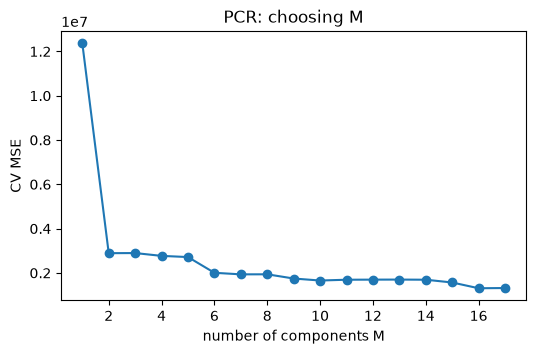

In [12]:
# Exercise 9(e)
pcr = Pipeline([("scale", StandardScaler()), ("pca", PCA()), ("lr", LinearRegression())])
pcr_grid = GridSearchCV(pcr, {"pca__n_components": range(1, Xc.shape[1] + 1)}, cv=cv10,
                        scoring="neg_mean_squared_error").fit(Xc_train, yc_train)
M_pcr = pcr_grid.best_params_["pca__n_components"]
test_mse_9["PCR"] = mean_squared_error(yc_test, pcr_grid.predict(Xc_test))
print(f"PCR: M = {M_pcr}, test MSE = {test_mse_9['PCR']:,.0f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, Xc.shape[1] + 1), -pcr_grid.cv_results_["mean_test_score"], marker="o")
ax.set(xlabel="number of components M", ylabel="CV MSE", title="PCR: choosing M")
plt.show()

### Exercise 9(f)

Fit a PLS model on the training set, with M chosen by crossvalidation. Report the test error obtained, along with the value
of M selected by cross-validation.

In [13]:
# Exercise 9(f)
pls = Pipeline([("scale", StandardScaler()), ("pls", PLSRegression(scale=False))])
pls_grid = GridSearchCV(pls, {"pls__n_components": range(1, Xc.shape[1] + 1)}, cv=cv10,
                        scoring="neg_mean_squared_error").fit(Xc_train, yc_train)
M_pls = pls_grid.best_params_["pls__n_components"]
test_mse_9["PLS"] = mean_squared_error(yc_test, pls_grid.predict(Xc_test).ravel())
print(f"PLS: M = {M_pls}, test MSE = {test_mse_9['PLS']:,.0f}")
cv_pls = pd.Series(-pls_grid.cv_results_["mean_test_score"], index=range(1, Xc.shape[1] + 1))
print("CV MSE by M:")
print(cv_pls.round(0).to_string())

PLS: M = 8, test MSE = 1,440,129
CV MSE by M:
1     2528442.0
2     1869902.0
3     1587693.0
4     1523208.0
5     1399057.0
6     1363952.0
7     1319812.0
8     1308307.0
9     1309923.0
10    1311683.0
11    1311898.0
12    1312080.0
13    1313117.0
14    1315229.0
15    1316872.0
16    1317087.0
17    1317220.0


### Exercise 9(g)

Comment on the results obtained. How accurately can we predict the number of college applications received? Is there much
difference among the test errors resulting from these five approaches?

In [14]:
# Exercise 9(g)
summary_9 = pd.DataFrame({"test MSE": test_mse_9})
summary_9["test RMSE"] = np.sqrt(summary_9["test MSE"])
summary_9["test R^2"] = 1 - summary_9["test MSE"] / np.mean((yc_test - yc_test.mean())**2)
display(summary_9.round(3))
print(f"Mean applications in the test set: {yc_test.mean():,.0f}; SD: {yc_test.std():,.0f}")

,test MSE,test RMSE,test R^2
Least squares,1425055.587,1193.757,0.918
Ridge,1546198.655,1243.462,0.911
Lasso,1411965.261,1188.261,0.919
PCR,1455919.862,1206.615,0.916
PLS,1440129.136,1200.054,0.917


Mean applications in the test set: 2,912; SD: 4,180


**Observations / conclusions**

On a 50/50 train/test split of the 777 colleges, test MSEs are:

| method | test MSE | test RMSE |
|---|---|---|
| Least squares | 1.43 M | 1,194 |
| Ridge (λ ≈ 5) | 1.55 M | 1,243 |
| Lasso (λ ≈ 6.7, 16 of 17 non-zero) | 1.41 M | 1,188 |
| PCR (M = 16) | 1.46 M | 1,207 |
| PLS (M = 8) | 1.44 M | 1,200 |

All five methods predict well: test $R^2 \approx 0.91$–0.92, and the RMSE (~1,200 applications) is small next to the spread of `Apps` (SD ≈ 4,200). The differences between them are small. With 17 predictors and ~390 training rows, ordinary least squares already has low variance, so shrinkage or dimension reduction gains almost nothing. CV picks almost all components for PCR, and the lasso drops only `F.Undergrad`. Most of the predictive power comes from `Accept`, which is nearly a direct proxy for applications.

---

## Exercise 10 · Applied

**Textbook: printed page 287**

We have seen that as the number of features used in a model increases,
the training error will necessarily decrease, but the test error may not.
We will now explore this in a simulated data set.

### Exercise 10(a)

Generate a data set with p = 20 features, n = 1,000 observations, and an associated quantitative response vector generated
according to the model
Y = Xβ + ϵ,
where β has some elements that are exactly equal to zero.

In [15]:
# Exercise 10(a)
rng = np.random.default_rng(10)
n, p = 1000, 20
X10 = rng.normal(size=(n, p))
beta_true = np.zeros(p)
nonzero_idx = [0, 2, 4, 7, 10, 13, 16, 19]
beta_true[nonzero_idx] = [2.0, -1.5, 1.0, 0.6, -0.4, 0.3, -0.25, 0.15]
y10 = X10 @ beta_true + rng.normal(scale=1.5, size=n)
print("True beta:", beta_true)

True beta: [ 2.    0.   -1.5   0.    1.    0.    0.    0.6   0.    0.   -0.4   0.
  0.    0.3   0.    0.   -0.25  0.    0.    0.15]


### Exercise 10(b)

Split your data set into a training set containing 100 observations
and a test set containing 900 observations.

In [16]:
# Exercise 10(b)
perm = rng.permutation(n)
tr, te = perm[:100], perm[100:]
X10_tr, X10_te, y10_tr, y10_te = X10[tr], X10[te], y10[tr], y10[te]
print(X10_tr.shape, X10_te.shape)

(100, 20) (900, 20)


### Exercise 10(c)

Perform best subset selection on the training set, and plot the
training set MSE associated with the best model of each size.

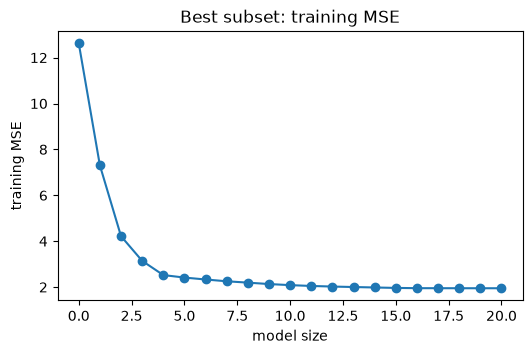

In [17]:
# Exercise 10(c)
# Exhaustive best-subset search over all 2^20 - 1 subsets. Using the Gram matrix makes each
# fit a small linear solve, so the full search takes well under a minute.
def best_subset(X, y):
    Xc_ = np.column_stack([np.ones(len(y)), X])
    G, b, yy = Xc_.T @ Xc_, Xc_.T @ y, y @ y
    best = {0: (yy - len(y) * y.mean()**2, ())}
    for k in range(1, X.shape[1] + 1):
        best_rss, best_cols = np.inf, None
        for cols in combinations(range(X.shape[1]), k):
            idx = (0,) + tuple(c + 1 for c in cols)
            Gs, bs_ = G[np.ix_(idx, idx)], b[list(idx)]
            rss = yy - bs_ @ np.linalg.solve(Gs, bs_)
            if rss < best_rss:
                best_rss, best_cols = rss, cols
        best[k] = (best_rss, best_cols)
    return best

best10 = best_subset(X10_tr, y10_tr)
train_mse = pd.Series({k: v[0] / len(y10_tr) for k, v in best10.items()}, name="train MSE")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(train_mse.index, train_mse.values, marker="o")
ax.set(xlabel="model size", ylabel="training MSE", title="Best subset: training MSE")
plt.show()

### Exercise 10(d)

Plot the test set MSE associated with the best model of each
size.

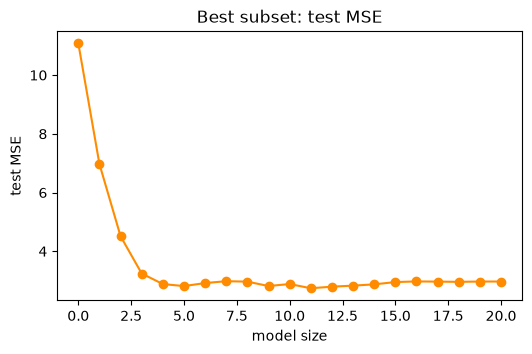

In [18]:
# Exercise 10(d)
def fit_subset(cols):
    if not cols:
        return np.full(p, 0.0), y10_tr.mean()
    lr = LinearRegression().fit(X10_tr[:, cols], y10_tr)
    beta = np.zeros(p)
    beta[list(cols)] = lr.coef_
    return beta, lr.intercept_

fits10 = {k: fit_subset(cols) for k, (_, cols) in best10.items()}
test_mse = pd.Series({k: np.mean((y10_te - (X10_te @ b + a))**2) for k, (b, a) in fits10.items()},
                     name="test MSE")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(test_mse.index, test_mse.values, marker="o", color="darkorange")
ax.set(xlabel="model size", ylabel="test MSE", title="Best subset: test MSE")
plt.show()

### Exercise 10(e)

For which model size does the test set MSE take on its minimum
value? Comment on your results. If it takes on its minimum value
for a model containing only an intercept or a model containing
all of the features, then play around with the way that you are
generating the data in (a) until you come up with a scenario in
which the test set MSE is minimized for an intermediate model
size.

In [19]:
# Exercise 10(e)
k_star = int(test_mse.idxmin())
print(f"Test MSE is minimised at model size {k_star} (MSE {test_mse[k_star]:.3f}); "
      f"irreducible error variance = {1.5**2:.2f}")
display(pd.DataFrame({"train MSE": train_mse, "test MSE": test_mse}).round(3).T)

Test MSE is minimised at model size 11 (MSE 2.741); irreducible error variance = 2.25


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
train MSE,12.626,7.304,4.217,3.143,2.523,2.415,2.331,2.253,2.194,2.132,...,2.049,2.023,2.002,1.983,1.964,1.953,1.951,1.95,1.949,1.949
test MSE,11.084,6.971,4.512,3.243,2.884,2.815,2.918,2.981,2.966,2.817,...,2.741,2.795,2.830,2.874,2.952,2.974,2.967,2.96,2.970,2.970


### Exercise 10(f)

How does the model at which the test set MSE is minimized
compare to the true model used to generate the data? Comment
on the coefficient values.

In [20]:
# Exercise 10(f)
b_star, a_star = fits10[k_star]
coef_table = pd.DataFrame({"true beta": beta_true, f"best {k_star}-variable model": b_star},
                          index=[f"X{j+1}" for j in range(p)])
print("Variables chosen:", [f"X{c+1}" for c in best10[k_star][1]])
print("True non-zero variables:", [f"X{c+1}" for c in nonzero_idx])
coef_table.round(3)

Variables chosen: ['X1', 'X3', 'X5', 'X7', 'X8', 'X11', 'X12', 'X14', 'X17', 'X19', 'X20']
True non-zero variables: ['X1', 'X3', 'X5', 'X8', 'X11', 'X14', 'X17', 'X20']


,true beta,best 11-variable model
X1,2.00,2.208
X2,0.00,0.000
X3,-1.50,-1.708
X4,0.00,0.000
X5,1.00,1.078
X6,0.00,0.000
X7,0.00,0.325
X8,0.60,0.781
X9,0.00,0.000
X10,0.00,0.000


### Exercise 10(g)

Create a plot displaying
G)p
j=1(βj −ˆβr
j )2 for a range of values
of r, where ˆβr
j is the jth coefficient estimate for the best model
containing r coefficients. Comment on what you observe. How
does this compare to the test MSE plot from (d)?

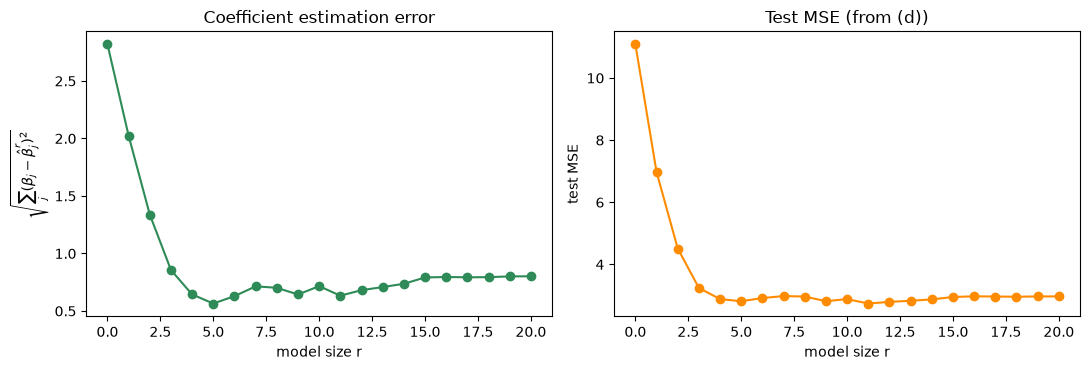

Coefficient error minimised at r = 5; test MSE minimised at r = 11


In [21]:
# Exercise 10(g)
coef_err = pd.Series({k: np.sqrt(np.sum((beta_true - b)**2)) for k, (b, _) in fits10.items()},
                     name="sqrt(sum (beta - beta_hat)^2)")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(coef_err.index, coef_err.values, marker="o", color="seagreen")
axes[0].set(xlabel="model size r", ylabel=r"$\sqrt{\sum_j (\beta_j - \hat\beta_j^r)^2}$",
            title="Coefficient estimation error")
axes[1].plot(test_mse.index, test_mse.values, marker="o", color="darkorange")
axes[1].set(xlabel="model size r", ylabel="test MSE", title="Test MSE (from (d))")
plt.tight_layout()
plt.show()
print(f"Coefficient error minimised at r = {coef_err.idxmin()}; test MSE minimised at r = {k_star}")

**Observations / conclusions**

Data: n = 1,000, p = 20, 8 non-zero coefficients (2, −1.5, 1, 0.6, −0.4, 0.3, −0.25, 0.15), noise SD 1.5. The training set has 100 rows and the test set 900.

- **(c)** Training MSE falls steadily as the model grows (12.6 → 1.95), as it must.
- **(d, e)** Test MSE drops quickly to ≈ 2.9 by size 4–5, is flat-ish through 10, and reaches its **minimum at size 11 (2.74)**. It then rises slightly to 2.97 for the full model. So an intermediate model size is best.
- **(f)** The 11-variable model contains all 8 true predictors plus 3 noise variables (X7, X12, X19, with small estimates around ±0.2–0.3). The large coefficients are well estimated (2.21 vs 2, −1.71 vs −1.5, 1.08 vs 1). The weakest true ones (−0.4, 0.15) are estimated less accurately.
- **(g)** The coefficient error $\sqrt{\sum_j(\beta_j-\hat\beta^r_j)^2}$ is smallest at **r = 5**. The test MSE curve is very flat between r = 5 and r = 11, so the two plots broadly agree: both fall sharply at first and then level off. But the model with the best test MSE is not always the one with the most accurate coefficients. Including small noisy terms can help prediction slightly while making individual estimates worse.

---

## Exercise 11 · Applied

**Textbook: printed page 287**

We will now try to predict per capita crime rate in the Boston data
set.

### Exercise 11(a)

Try out some of the regression methods explored in this chapter,
such as best subset selection, the lasso, ridge regression, and
PCR. Present and discuss results for the approaches that you
consider.

In [22]:
# Exercise 11(a)
Boston = load_data("Boston")
Xb = Boston.drop(columns="crim")
yb = Boston["crim"]
cvb = KFold(10, shuffle=True, random_state=0)
cv_mse = lambda model, X=Xb: -cross_val_score(model, X, yb, cv=cvb, scoring="neg_mean_squared_error").mean()

results_11 = {}
results_11["Least squares (all 12)"] = cv_mse(LinearRegression())

# Best subset: for each size k, pick the best subset by training RSS, then compare sizes by 10-fold CV.
subset_by_size = {}
for k in range(1, Xb.shape[1] + 1):
    subset_by_size[k] = min(combinations(Xb.columns, k),
                            key=lambda cols: sm.OLS(yb, sm.add_constant(Xb[list(cols)])).fit().ssr)
subset_cv = pd.Series({k: cv_mse(LinearRegression(), Xb[list(c)]) for k, c in subset_by_size.items()})
k_b = int(subset_cv.idxmin())
results_11[f"Best subset (k={k_b})"] = subset_cv[k_b]

ridge_b = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 4, 200)))
lasso_b = make_pipeline(StandardScaler(), LassoCV(alphas=200, cv=5, max_iter=100_000))
results_11["Ridge"] = cv_mse(ridge_b)
results_11["Lasso"] = cv_mse(lasso_b)

pcr_b = GridSearchCV(Pipeline([("s", StandardScaler()), ("pca", PCA()), ("lr", LinearRegression())]),
                     {"pca__n_components": range(1, 13)}, cv=5, scoring="neg_mean_squared_error")
results_11["PCR"] = cv_mse(pcr_b)
results_11["Intercept only"] = np.mean((yb - yb.mean())**2)

print("Best subset sequence:")
for k, c in subset_by_size.items():
    print(f"  k={k:2d}  CV MSE={subset_cv[k]:7.3f}  {c}")
display(pd.Series(results_11, name="10-fold CV MSE").sort_values().round(3).to_frame())

Best subset sequence:
  k= 1  CV MSE= 46.208  ('rad',)
  k= 2  CV MSE= 44.251  ('rad', 'lstat')
  k= 3  CV MSE= 44.143  ('rad', 'lstat', 'medv')
  k= 4  CV MSE= 43.426  ('zn', 'dis', 'rad', 'medv')
  k= 5  CV MSE= 43.146  ('zn', 'indus', 'dis', 'rad', 'medv')
  k= 6  CV MSE= 42.954  ('zn', 'nox', 'dis', 'rad', 'ptratio', 'medv')
  k= 7  CV MSE= 42.811  ('zn', 'nox', 'dis', 'rad', 'ptratio', 'lstat', 'medv')
  k= 8  CV MSE= 42.701  ('zn', 'indus', 'nox', 'dis', 'rad', 'ptratio', 'lstat', 'medv')
  k= 9  CV MSE= 42.978  ('zn', 'indus', 'nox', 'rm', 'dis', 'rad', 'ptratio', 'lstat', 'medv')
  k=10  CV MSE= 43.054  ('zn', 'chas', 'nox', 'rm', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv')
  k=11  CV MSE= 43.018  ('zn', 'indus', 'chas', 'nox', 'rm', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv')
  k=12  CV MSE= 43.107  ('zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv')


,10-fold CV MSE
Best subset (k=8),42.701
Ridge,43.055
PCR,43.104
Least squares (all 12),43.107
Lasso,43.332
Intercept only,73.840


### Exercise 11(b)

Propose a model (or set of models) that seem to perform well on
this data set, and justify your answer. Make sure that you are
evaluating model performance using validation set error, crossvalidation, or some other reasonable alternative, as opposed to
using training error.

In [23]:
# Exercise 11(b)
# Repeat the comparison on a held-out test set as a second check.
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.3, random_state=2)
models_11 = {
    "Least squares": LinearRegression(),
    f"Best subset (k={k_b})": None,
    "Ridge": ridge_b, "Lasso": lasso_b, "PCR": pcr_b,
}
test_11 = {}
for name, m in models_11.items():
    if m is None:
        cols = list(subset_by_size[k_b])
        pred = LinearRegression().fit(Xb_tr[cols], yb_tr).predict(Xb_te[cols])
    else:
        pred = m.fit(Xb_tr, yb_tr).predict(Xb_te)
    test_11[name] = mean_squared_error(yb_te, pred)
display(pd.Series(test_11, name="hold-out test MSE").sort_values().round(3).to_frame())

,hold-out test MSE
Best subset (k=8),25.862
PCR,26.175
Least squares,26.175
Ridge,26.512
Lasso,26.836


### Exercise 11(c)

Does your chosen model involve all of the features in the data
set? Why or why not?

In [24]:
# Exercise 11(c)
lasso_full = lasso_b.fit(Xb, yb)
coef_b = pd.Series(lasso_full[-1].coef_, index=Xb.columns)
print(f"Lasso on all data: lambda = {lasso_full[-1].alpha_:.4f}; non-zero = {(coef_b != 0).sum()} of {len(coef_b)}")
print(coef_b.round(3).to_string())
print(f"\nBest-subset model uses {k_b} of 12 predictors: {subset_by_size[k_b]}")

Lasso on all data: lambda = 0.3463; non-zero = 4 of 12
zn         0.000
indus     -0.000
chas      -0.000
nox        0.000
rm         0.000
age        0.000
dis       -0.203
rad        4.231
tax        0.000
ptratio   -0.000
lstat      0.928
medv      -0.641

Best-subset model uses 8 of 12 predictors: ('zn', 'indus', 'nox', 'dis', 'rad', 'ptratio', 'lstat', 'medv')


**Observations / conclusions**

- **(a)** 10-fold CV MSE for predicting `crim`: best subset with 8 variables 42.7, ridge 43.1, PCR 43.1, least squares 43.1, lasso 43.3. The intercept-only model scores 73.8. Every method cuts the CV error by about 40% compared with the intercept-only model, and they are all within about 1.5% of each other.
- **(b)** A separate 70/30 hold-out also puts best subset first: the 8-variable model has test MSE 25.9, and the others are 26.2–26.8 (the order of the other methods changes slightly). I propose the **8-variable best-subset model** (`zn, indus, nox, dis, rad, ptratio, lstat, medv`). A sparser **lasso** model is almost as good and easier to interpret. Caveat: the best subset of each size was found on the full data before cross-validating over the size, so its CV error is slightly optimistic.
- **(c)** No. Several predictors (`chas`, `rm`, `age`, `tax`) add nothing once the others are in the model. With all the data, the lasso keeps only 4 (`rad`, `lstat`, `medv`, `dis`), and `rad` dominates. Crime is heavily concentrated in tracts with `rad` = 24, so extra correlated variables mostly add variance. The response is also extremely skewed (a few tracts have crim > 30), which explains why the MSEs are large in absolute terms.